In [2]:
# ============================================================
# SETUP: load the feature-engineered dataset (post-M3, not the
# raw M2 output) — this file is what M5/M6 will actually train
# on, so EDA needs to validate THESE columns, including engineered
# features like lags/rolling stats/v_c_ratio, not just raw sensor data.
# ============================================================
import pandas as pd
import numpy as np

df = pd.read_parquet("../data/processed/flowcast_features.parquet")
print("Shape:", df.shape)

# Key columns for EDA: the core sensor readings + weather fields
# most likely to matter for modelling. Not every one of the 71
# columns needs its own deep-dive — this is a representative set.
key_cols = [
    "traffic_volume", "avg_speed", "occupancy", "travel_time",
    "accident_count", "v_c_ratio", "temperature", "rainfall", "visibility"
]

Shape: (176701, 71)


## 1. Descriptive Statistics (mean, median, mode)

Per PRD 10.1: used here for EDA summaries, and this is the same
concept underlying M2's median-based imputation and mode-based
categorical fills. Comparing mean vs. median per column is a quick
skew check — a large gap signals a skewed distribution.

In [3]:
# ============================================================
# Compute mean, median, mode, std, min, max for each key numeric
# column. Comparing mean vs. median reveals skew: if they're close,
# the distribution is roughly symmetric; if far apart, it's skewed.
# ============================================================
desc_stats = df[key_cols].describe().T
desc_stats["median"] = df[key_cols].median()
desc_stats["mode"] = df[key_cols].mode().iloc[0]  # mode() can return multiple rows if tied — take the first

print(desc_stats[["mean", "median", "mode", "std", "min", "max"]].round(2))

# Mode is more meaningful for categorical columns than continuous
# ones (a continuous variable's "most common exact value" is often
# not particularly informative) — check these separately.
print("\nMode of categorical columns:")
print(df[["congestion_level", "weather_condition_clean"]].mode().iloc[0])

                   mean    median      mode      std     min       max
traffic_volume   431.50    362.00    149.00   283.12   41.00   2090.00
avg_speed         42.11     44.90     51.70    11.37    6.70     64.80
occupancy         31.17     27.00     12.60    19.58    3.00    100.00
travel_time        3.57      3.12      3.21     2.53    0.80     29.91
accident_count     0.01      0.00      0.00     0.10    0.00      2.00
v_c_ratio          0.46      0.40      0.18     0.29    0.05      1.83
temperature       17.98     18.00     17.70     4.38    5.80     29.80
rainfall           0.19      0.00      0.00     1.06    0.00      8.90
visibility      9672.17  10000.00  10000.00  1504.06  301.00  10000.00

Mode of categorical columns:
congestion_level           Free-flow
weather_condition_clean        Clear
Name: 0, dtype: str


### Investigating traffic_volume's mode (149.0)

Initial hypothesis: this repeated value might be an artifact of M2's
grouped-median imputation (~4,600 missing traffic_volume values filled
with group medians could inflate one value's frequency). Testing this
by checking whether 149.0 clusters within specific road/hour groups
(would confirm imputation artifact) or spreads broadly (would suggest
it's just a naturally common sensor count).

In [4]:
# ============================================================
# Check whether the mode (149.0) is concentrated in specific
# road/hour groups (imputation signature) or spread broadly
# (naturally common value, nothing to flag).
# ============================================================
top_value_rows = df[df["traffic_volume"] == 149.0]
print("Spread across roads:", top_value_rows["road_id"].nunique(), "unique roads")
print("Spread across hours:", top_value_rows["hour"].nunique(), "unique hours")
print(top_value_rows["road_id"].value_counts().head())

# RESULT: spread across all 25 roads and 15 hours, no single road
# dominating (max ~10% of occurrences) — hypothesis REJECTED.
# Conclusion: 149.0 is a naturally common integer traffic count
# across a 25-road corridor with thousands of time windows, not a
# pipeline side effect. Verified rather than assumed.

Spread across roads: 25 unique roads
Spread across hours: 15 unique hours
road_id
NL-013    57
NL-011    49
NL-025    45
NL-022    34
NL-009    33
Name: count, dtype: int64


## 2. Standard Deviation & Variance

Per PRD 10.1: underpins rolling-window volatility features (M3) and
spread analysis here. Variance = std². Also computing coefficient of
variation (CV = std/mean) to fairly compare relative dispersion across
columns with very different scales/units (e.g. visibility in meters
vs. rainfall in mm).

In [5]:
# ============================================================
# Standard deviation, variance, and coefficient of variation
# (CV) per key column. CV normalizes std by the mean, so columns
# on very different scales (visibility ~10,000 vs rainfall ~9) can
# be fairly compared for RELATIVE volatility, not just raw spread.
# ============================================================
spread_stats = df[key_cols].agg(["std", "var"]).T
spread_stats["coefficient_of_variation"] = spread_stats["std"] / df[key_cols].mean()
print(spread_stats.round(3))

# ============================================================
# Connect to M3's engineered rolling-std features: is LOCAL,
# recent volatility (2h/4h window, per road) smaller than the
# dataset's OVERALL volatility? Expected: yes — a short window on
# one road should vary less than the full 5-month, 25-road dataset.
# ============================================================
print("\nRolling std features (from M3) vs. raw std:")
print(df[["traffic_volume", "traffic_volume_rolling_std_4", "traffic_volume_rolling_std_8"]].describe())

                     std          var  coefficient_of_variation
traffic_volume   283.121    80157.760                     0.656
avg_speed         11.372      129.332                     0.270
occupancy         19.585      383.556                     0.628
travel_time        2.529        6.394                     0.709
accident_count     0.098        0.010                    10.340
v_c_ratio          0.286        0.082                     0.623
temperature        4.377       19.157                     0.243
rainfall           1.059        1.121                     5.523
visibility      1504.064  2262209.478                     0.156

Rolling std features (from M3) vs. raw std:
       traffic_volume  traffic_volume_rolling_std_4  \
count   176701.000000                 176601.000000   
mean       431.496675                     81.385315   
std        283.121459                     68.759175   
min         41.000000                      0.000002   
25%        195.000000                   

### Class Imbalance: Accident Risk

accident_count is extremely imbalanced: 99.06% of rows have 0
accidents, 0.93% have 1, and 0.008% have 2. A naive "always predict
no accident" classifier would achieve 99% accuracy while being
completely uninformative — this is why the PRD specifies ROC-AUC
(not accuracy) for the accident-risk classification target.
Given only 15 rows have accident_count=2, framing this target as
binary (accident_flag: 0 vs 1+) rather than 3-class is likely more
tractable — a decision to carry into M5.

In [6]:
print(df["accident_count"].value_counts())

accident_count
0    175049
1      1637
2        15
Name: count, dtype: int64


## 3. Correlation Analysis

Per PRD 10.1: correlation guides feature selection (which features
actually relate to the target) and spots redundancy (which engineered
features are so similar to each other that one adds little). Two
separate checks: feature-TARGET correlation (traffic_volume, the
primary regression target) and feature-FEATURE correlation (checking
M3's engineered features against each other and against raw columns
they were derived from).

In [7]:
# ============================================================
# Feature-target correlation: which columns actually relate to
# traffic_volume (primary regression target per PRD Section 11.1)?
# Only numeric columns can be correlated — excludes road_id,
# congestion_level, weather_condition_clean, temperature_band
# (string columns; their encoded versions are included instead).
# ============================================================
numeric_df = df.select_dtypes(include=[np.number, bool])

target_corr = numeric_df.corr()["traffic_volume"].sort_values(ascending=False)
print("Top 15 features correlated with traffic_volume:")
print(target_corr.head(15))
print("\nBottom 10 (weakest / negative correlation):")
print(target_corr.tail(10))

Top 15 features correlated with traffic_volume:
traffic_volume                   1.000000
vehicle_count                    0.998345
v_c_ratio                        0.948644
occupancy                        0.938033
traffic_volume_lag_1             0.930047
traffic_volume_lag_2             0.833215
traffic_volume_rolling_mean_4    0.791217
traffic_volume_lag_48            0.790653
signal_timing                    0.761485
traffic_volume_rolling_std_4     0.632467
pct_car                          0.595077
traffic_volume_rolling_mean_8    0.559305
is_rush_hour                     0.550114
travel_time                      0.534026
avg_speed_rolling_std_4          0.518741
Name: traffic_volume, dtype: float64

Bottom 10 (weakest / negative correlation):
avg_speed_rolling_mean_8   -0.446388
pct_hcv                    -0.517484
hour_cos                   -0.529512
pct_2w                     -0.541141
avg_speed_lag_48           -0.680885
avg_speed_rolling_mean_4   -0.688331
avg_speed_lag_2   

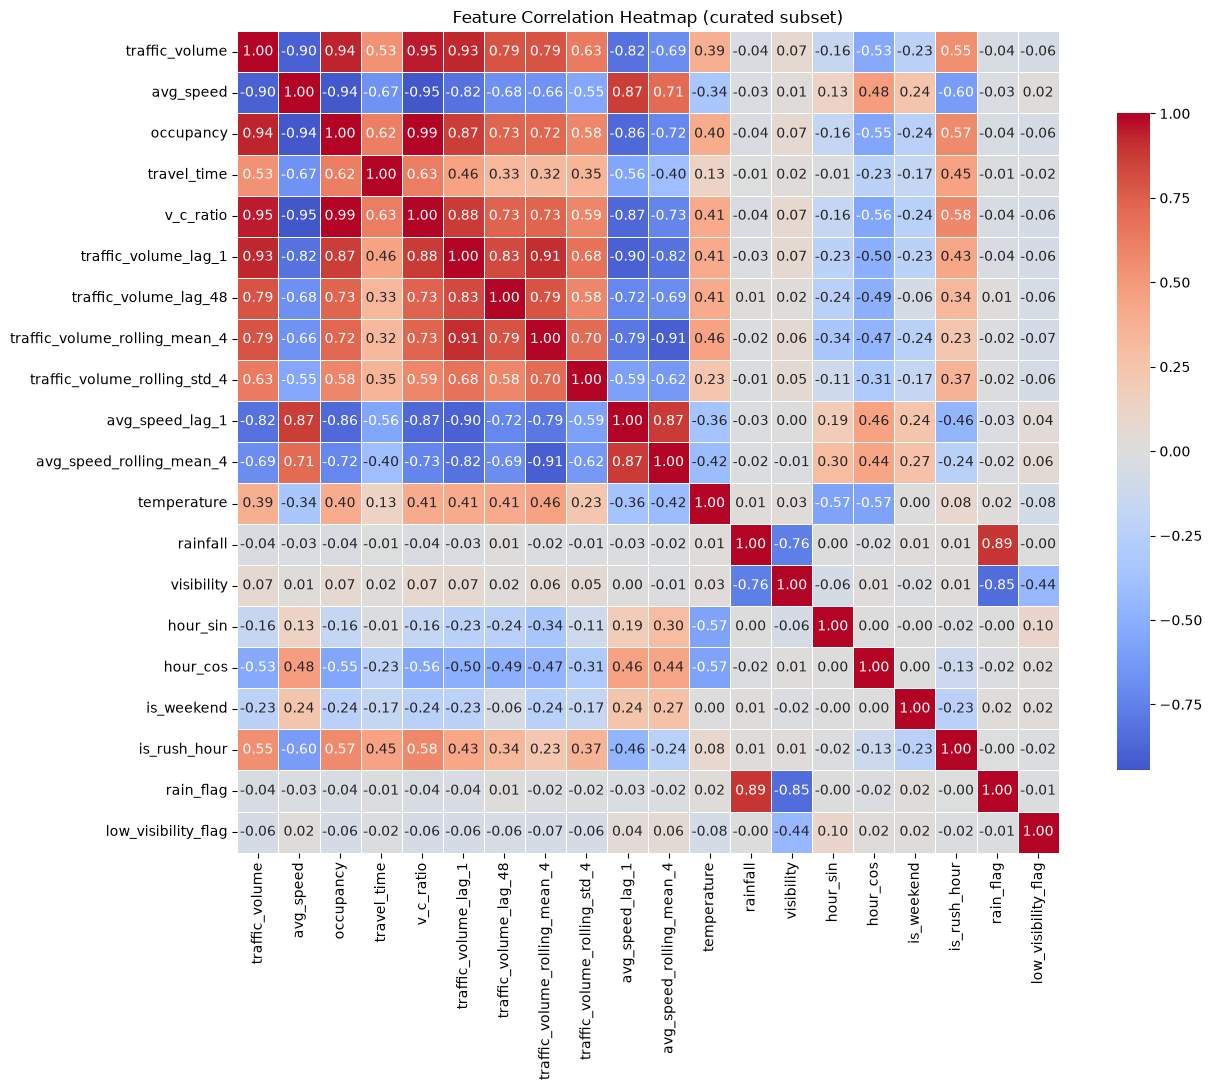

In [8]:
# ============================================================
# Visual correlation heatmap of the full engineered feature set,
# per PRD's Visualisation tooling (Matplotlib/Seaborn). Restricted
# to a curated subset of ~20 columns — a 71-column heatmap would
# be unreadable, so this focuses on primary raw fields, targets,
# and one representative from each engineered feature family.
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

heatmap_cols = [
    "traffic_volume", "avg_speed", "occupancy", "travel_time", "v_c_ratio",
    "traffic_volume_lag_1", "traffic_volume_lag_48",
    "traffic_volume_rolling_mean_4", "traffic_volume_rolling_std_4",
    "avg_speed_lag_1", "avg_speed_rolling_mean_4",
    "temperature", "rainfall", "visibility",
    "hour_sin", "hour_cos", "is_weekend", "is_rush_hour",
    "rain_flag", "low_visibility_flag",
]

corr_matrix = numeric_df[heatmap_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Heatmap (curated subset)")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150)
plt.show()

### Target Leakage Risk: v_c_ratio and capacity_headroom

Both v_c_ratio (r=0.948) and capacity_headroom (r=-0.836) show very
high correlation with traffic_volume — expected, since both are
mathematically derived FROM traffic_volume in M3 (v_c_ratio =
traffic_volume / (road_capacity/2)). These must be EXCLUDED from the
feature set when traffic_volume is the regression target (M5), since
including them would let the model trivially reconstruct the answer
via near-algebraic inversion rather than learning genuine patterns.
They remain valid features for OTHER targets (e.g. congestion_level
classification), where they represent legitimate derived signal
rather than a restatement of the target itself.

### Possible Redundant Column: vehicle_count
vehicle_count correlates at 0.998 with traffic_volume — check the
data dictionary to confirm whether these are meant to be genuinely
distinct measurements; if this near-duplication is confirmed, one
should likely be dropped before modelling to avoid wasted/redundant
model capacity.

## 4. Covariance & Multicollinearity (VIF)

Per PRD 10.1: covariance underpins correlation and multicollinearity
checks. Correlation (step 3) is covariance normalized to [-1,1] —
here we look at raw covariance, then formally quantify
multicollinearity using VIF (Variance Inflation Factor), which
catches redundancy across MULTIPLE features combined, not just pairs.

In [9]:
# ============================================================
# Covariance matrix — same underlying concept as correlation
# (step 3), but in raw, UNNORMALIZED units. Less directly
# interpretable across columns of different scales (that's exactly
# why correlation, which normalizes covariance by each variable's
# std, is generally more useful for comparison) — shown here mainly
# to explicitly satisfy the PRD's named concept, with correlation
# remaining the primary tool for interpretation.
# ============================================================
cov_matrix = numeric_df[heatmap_cols].cov()
print("Covariance matrix (subset):")
print(cov_matrix.round(1))

Covariance matrix (subset):
                               traffic_volume  avg_speed  occupancy  \
traffic_volume                        80157.8    -2888.3     5201.2   
avg_speed                             -2888.3      129.3     -208.3   
occupancy                              5201.2     -208.3      383.6   
travel_time                             382.3      -19.3       30.7   
v_c_ratio                                76.7       -3.1        5.5   
traffic_volume_lag_1                  74548.4    -2640.3     4811.7   
traffic_volume_lag_48                 63520.4    -2185.8     4043.7   
traffic_volume_rolling_mean_4         59950.5    -2004.6     3791.9   
traffic_volume_rolling_std_4          12311.1     -429.7      784.5   
avg_speed_lag_1                       -2645.6      112.5     -190.9   
avg_speed_rolling_mean_4              -2024.8       83.5     -146.3   
temperature                             479.9      -17.0       34.7   
rainfall                                -11.1    

Covariance values are not directly comparable across differently-scaled
columns (e.g. visibility's raw covariance values appear far larger than
rain_flag's purely due to unit scale, not stronger relationships) —
correlation (Section 3) remains the primary tool used for interpretation.

In [11]:
# ============================================================
# Variance Inflation Factor (VIF): for each feature, how well can
# it be predicted from a LINEAR COMBINATION of all the other
# features? VIF > 5 is commonly flagged as concerning, VIF > 10 as
# severe multicollinearity. This catches redundancy that pairwise
# correlation alone can miss (a feature might not correlate strongly
# with any ONE other feature, yet still be redundant given several
# combined).
#
# IMPORTANT: exclude v_c_ratio, capacity_headroom, and vehicle_count
# here — we already know these are near-duplicates/derivations of
# traffic_volume (step 3 finding), so including them would just
# produce enormous, uninformative VIF scores that restate what we
# already confirmed, rather than surfacing NEW multicollinearity.
# ============================================================
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_cols = [
    "traffic_volume", "avg_speed", "occupancy", "travel_time",
    "traffic_volume_lag_1", "traffic_volume_lag_48",
    "traffic_volume_rolling_mean_4", "traffic_volume_rolling_std_4",
    "avg_speed_lag_1", "avg_speed_rolling_mean_4",
    "temperature", "rainfall", "visibility",
    "hour_sin", "hour_cos", "is_weekend", "is_rush_hour",
]

vif_df = numeric_df[vif_cols].dropna()  # VIF can't handle NaN (from the lag/rolling series starts)

vif_results = pd.DataFrame()
vif_results["feature"] = vif_cols
vif_results["VIF"] = [
    variance_inflation_factor(vif_df.values, i) for i in range(len(vif_cols))
]
vif_results = vif_results.sort_values("VIF", ascending=False)
print(vif_results.round(2))

                          feature    VIF
4            traffic_volume_lag_1  51.81
6   traffic_volume_rolling_mean_4  45.19
0                  traffic_volume  34.48
9        avg_speed_rolling_mean_4  27.73
8                 avg_speed_lag_1  24.63
2                       occupancy  16.91
1                       avg_speed  16.44
5           traffic_volume_lag_48   3.74
10                    temperature   2.86
14                       hour_cos   2.67
12                     visibility   2.47
11                       rainfall   2.40
7    traffic_volume_rolling_std_4   2.33
13                       hour_sin   2.28
16                   is_rush_hour   2.11
3                     travel_time   2.05
15                     is_weekend   1.26


### Multicollinearity (VIF Analysis)

VIF analysis revealed severe multicollinearity (VIF > 10) among:
traffic_volume_lag_1 (51.8), traffic_volume_rolling_mean_4 (45.2),
traffic_volume (34.5), avg_speed_rolling_mean_4 (27.7),
avg_speed_lag_1 (24.6), occupancy (16.9), avg_speed (16.4).

This is expected — these features all derive from the same underlying
traffic signal at different time offsets. Implication for M5: tree-
based models (Decision Tree, Random Forest, XGBoost) are largely
unaffected by multicollinearity and can use the full feature set.
Linear Regression and SVM, however, will need either a reduced
feature subset (e.g. one lag + one rolling window, not both) or
regularization (Ridge/Lasso) to produce stable, interpretable
coefficients.

### vehicle_count vs traffic_volume (resolved)

Per the data dictionary: traffic_volume is "vehicles observed in the
window" (the primary regression target); vehicle_count is the "raw
sensor count before flow adjustment." These are not duplicate columns
— vehicle_count is an earlier-stage measurement that traffic_volume is
derived/adjusted from. Their 0.998 correlation is expected given this
relationship, but it means vehicle_count carries near-direct
information about the target and must be EXCLUDED from the feature
set when traffic_volume is the regression target — the same
target-leakage concern as v_c_ratio and capacity_headroom, arguably
more severe since vehicle_count is closer to being a pre-adjustment
version of the target itself, rather than merely a derived ratio.

In [12]:
print("Rows used for VIF:", len(vif_df), "out of", len(numeric_df))
print("Rows dropped (NaN in lag/rolling features):", len(numeric_df) - len(vif_df))

Rows used for VIF: 171069 out of 176701
Rows dropped (NaN in lag/rolling features): 5632


### VIF Data Coverage Note
VIF was computed on 171,069 of 176,701 rows (96.8%) — 5,632 rows
(3.2%) were dropped due to NaN values in lag/rolling features (the
expected per-road series-start nulls from M3, e.g. traffic_volume_lag_48
alone contributes ~1,200). This coverage is high enough that the VIF
results are representative of the full dataset.

### vehicle_count vs traffic_volume (resolved)
Per the data dictionary: traffic_volume is "vehicles observed in the
window" (primary regression target); vehicle_count is the "raw sensor
count before flow adjustment" — an earlier-stage measurement, not a
duplicate column. Their 0.998 correlation is expected, but this means
vehicle_count carries near-direct information about the target and
must be EXCLUDED from the feature set when traffic_volume is the
regression target — the same leakage concern as v_c_ratio and
capacity_headroom, arguably more severe.

## 5. Distributions & Normality Check

Per PRD 10.1: normal distribution underlies z-score outlier detection
and residual analysis. M2 deliberately used grouped IQR instead of
z-score for outlier detection (Section: Statistical Outlier Handling)
— this step checks whether that was justified, by examining whether
key sensor readings are actually normally distributed.

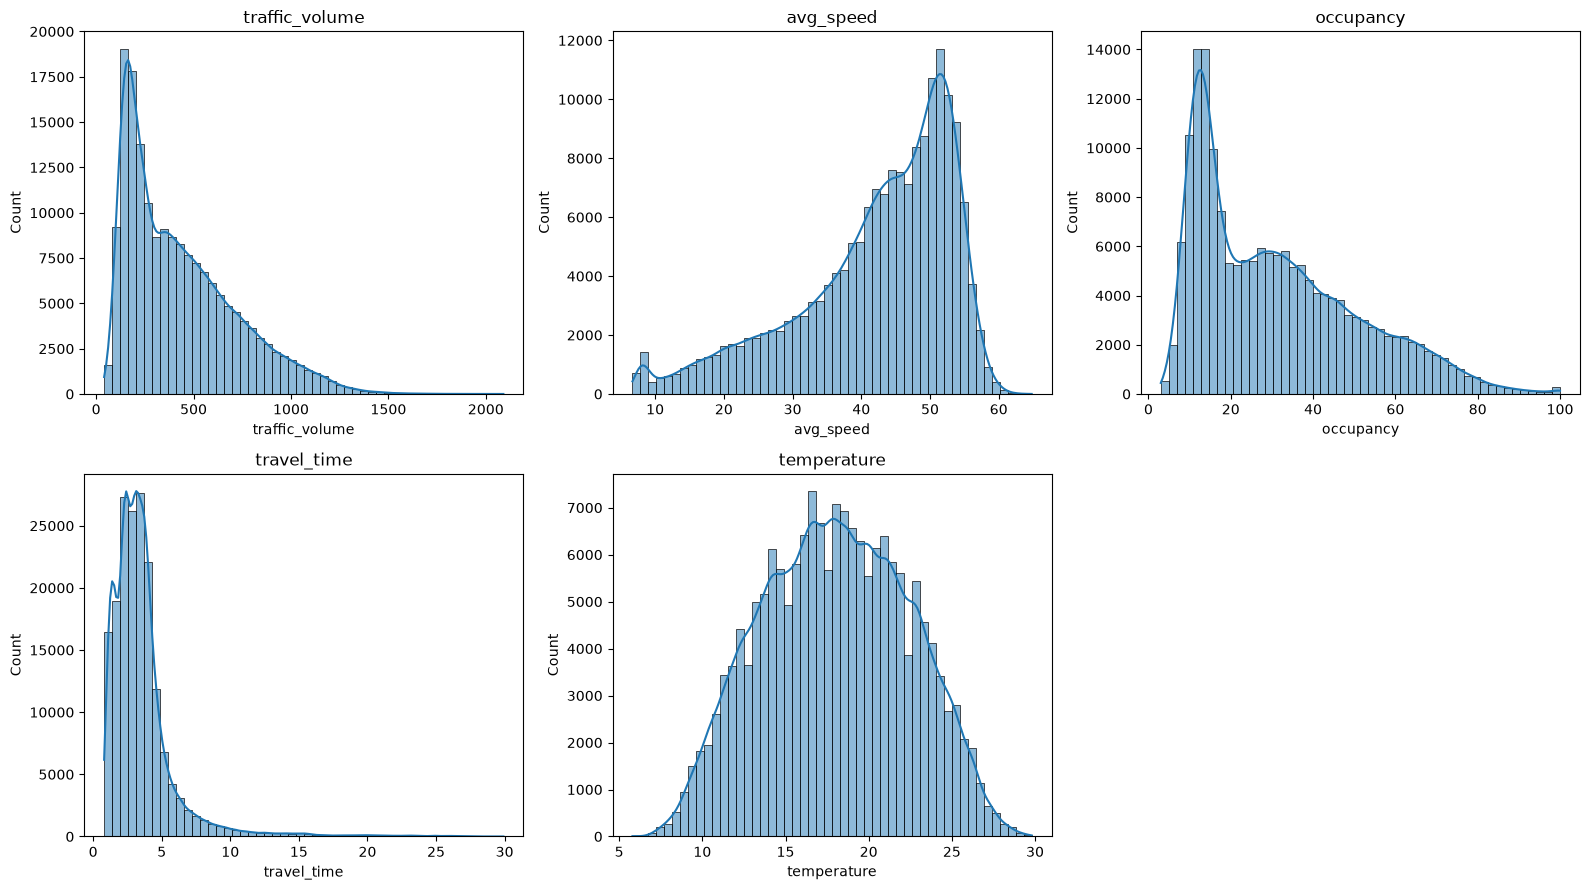

In [13]:
# ============================================================
# Histograms with KDE overlay for key continuous columns.
# Visual first pass: does each distribution look roughly bell-shaped
# (normal), skewed, or multi-modal?
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

dist_cols = ["traffic_volume", "avg_speed", "occupancy", "travel_time", "temperature"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(dist_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=50)
    axes[i].set_title(col)

axes[-1].axis("off")  # hide the unused 6th subplot
plt.tight_layout()
plt.savefig("../reports/figures/distributions.png", dpi=150)
plt.show()

In [14]:
# ============================================================
# Formal normality assessment:
# - Skewness: 0 = symmetric, >0 = right tail, <0 = left tail
# - Kurtosis: 0 = normal "peakedness", >0 = heavier tails than normal
# - D'Agostino-Pearson test (scipy.stats.normaltest): formally tests
#   the null hypothesis "this sample comes from a normal
#   distribution." Used instead of Shapiro-Wilk because Shapiro-Wilk
#   is unreliable/impractical at this sample size (176K rows);
#   normaltest is designed for larger samples.
# p < 0.05 => reject normality (statistically significant deviation)
# ============================================================
from scipy import stats

normality_results = []
for col in dist_cols:
    data = df[col].dropna()
    skewness = stats.skew(data)
    kurt = stats.kurtosis(data)
    stat, p_value = stats.normaltest(data)
    normality_results.append({
        "column": col,
        "skewness": round(skewness, 3),
        "kurtosis": round(kurt, 3),
        "normaltest_p": p_value,
        "approx_normal": p_value > 0.05,
    })

normality_df = pd.DataFrame(normality_results)
print(normality_df)

           column  skewness  kurtosis  normaltest_p  approx_normal
0  traffic_volume     0.998     0.520           0.0          False
1       avg_speed    -1.010     0.411           0.0          False
2       occupancy     0.833    -0.061           0.0          False
3     travel_time     3.647    20.500           0.0          False
4     temperature    -0.002    -0.720           0.0          False


### Normality Check

All 5 key sensor columns formally reject normality (D'Agostino-Pearson
test, p<0.001 for all). traffic_volume and occupancy are right-skewed
(vehicle counts have a natural floor at 0 with occasional high spikes);
avg_speed is left-skewed with a visible secondary low-speed cluster
corresponding to severe congestion — visual confirmation of the
bimodality that motivated M2's use of grouped IQR (rather than global
z-score, which assumes normality) for outlier detection. travel_time
shows the most extreme non-normality (skew=3.65, kurtosis=20.5) —
heavy-tailed, likely driven by rare severe-congestion events.

temperature is a notable exception: skewness≈0 and the histogram
appears visually bell-shaped, yet the formal test still rejects
normality — attributable to the test's high statistical power at
n=176,701, where even minor deviations become "significant." This
illustrates a real distinction between statistical and practical
significance.

**Conclusion:** M2's decision to use grouped IQR rather than z-score
for outlier detection is retroactively justified by this analysis —
the underlying sensor readings are not normally distributed, so a
method assuming normality would have been statistically inappropriate.